# Marketing Science Empirical Analysis — Step-by-Step Story Progression

Evaluation of `KEV-0.8B`, `KEV-4B`, and `KEV-9B` across the paper's four-step narrative using two universal metrics shared across all benchmarks: **Population Slope MSE ($\beta\text{ MSE}$)** and **Choice-Distribution KL Divergence ($\text{Choice KL}$)**.

### Dataset Roles
- **Training studies**:
  - `Wu 2025` (electricity-plan conjoint: monthly bill, share of renewables, locally produced renewables): either **8 published OLS slopes** (`Row 2`, `Row 4`) or **`18,591` respondent microdata choices** (`Row 2b`, `Row 5`).
  - `Berke 2023` (drone-delivery choice experiment: delivery fee, wait time, privacy): respondent choices (`Row 3`, `Row 4`, `Row 5`).
- **Validation & checkpoint selection (`best.pt`)**: `Kriner 2026` (flight conjoint, 12 terms; no training study is about flights).
- **Held-out test sets (`test_best/`)**:
  - `Grummon 2025` (food warning labels, 5 terms).
  - `Kreps 2020` (`Kreps et al. 2020` vaccine conjoint, 11 terms; `1,971` respondents, `9,855` tasks).

### Narrative Roadmap
- **Step 0 — Run & `test_best` Inventory**: Training status (`runs-rorqual/`) and `test_best/` completion.
- **Overview — The Story at a Glance**: Table 0, Figure 0 (change on Kriner vs. on the held-out test sets for every main regime).
- **Step 1 — Microdata Fine-Tuning Transfers to Unseen Domains (Untrained vs. `Row 2b`, `Row 3`, `Row 5`)**: Table 1, Figure 1; Choice KL in Table A2.
- **Step 2 — A Published Table Teaches the Study's Slopes (Untrained vs. `Row 2` KL-anchored vs. `Row 2b`)**: Table 2, Figure 2; Choice KL in Table A3.
- **Step 3 — Your Microdata + Another Study's Table (Untrained vs. `Row 3` vs. `Row 4` KL-anchored vs. `Row 5`)**: Table 3, Figure 3; Choice KL in Table A4.
- **Step 4 — Where the Table Helps (`Kriner 2026` flight slopes by attribute; `Row 3` vs. `Row 4` vs. `Row 5`)**: Figure 4 (model − human), Figure 5 (human and model slopes); numbers in Table A6. `Kreps 2020` slopes by attribute in Table A5.
- **Ablation — The KL Anchor** (validation set Kriner 2026 only): Table 4 (with vs. without the anchor, `Row 2` and `Row 4`), Figures 6–7 (Kriner 2026 over training), Table 5 (α sweep); Choice KL in Table A7.

In [231]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from cycler import cycler

# Repository academic palette ("nature") & neutral tones (cf. code/analysis/wang2026/wang_mnl.py)
PALETTE_NAME = "lancet"
PALETTES = {
    "nature": ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"],
    "lancet": ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"],
}
NEUTRALS = {
    "text": "#2B2B2B",
    "muted": "#52514E",
    "ref_line": "#6E6A64",
    "baseline": "#9A9893",
    "grid": "#D4D2CC",
    "legend_edge": "#E0DED8",
}
PAL = PALETTES[PALETTE_NAME]
plt.rcParams["axes.prop_cycle"] = cycler(color=PAL)

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 240)

CODE_DIR = next(
    (c for p in (Path.cwd(), *Path.cwd().parents) for c in (p, p / "code") if all((c / d).is_dir() for d in ("kev", "data", "training"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and training/ at or above {Path.cwd()}")

BETA_TRAINING_DIR = CODE_DIR / "train-notebooks" / "beta-training"
PAPER_DIR = BETA_TRAINING_DIR / "ms_paper_beta_loss"
PAPER_RUNS_ROOT = PAPER_DIR / "runs-rorqual"
# Regime runs pulled from each cluster; one regime run lives in exactly one of these
REGIME_RUN_ROOTS = (PAPER_DIR / "runs-rorqual", PAPER_DIR / "runs-nibi")
LOCAL_PAPER_RUNS_ROOT = PAPER_DIR / "runs"
LEGACY_RUNS_ROOT = BETA_TRAINING_DIR / "runs"
TEST_BEST_SUBDIR = "test_best"

os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(BETA_TRAINING_DIR), str(PAPER_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from beta_ce_population.trainer import load_ce_population_run
from beta_population.trainer import load_population_run
from beta_train import runs as run_store
from beta_train.trainer import load_run
from paper_beta import extract_step0_from_run_dir, load_paper_run

MODEL_SLUGS = ("kev-0.8b", "kev-4b", "kev-9b")
MODEL_DISPLAY = {
    "kev-0.8b": "KEV-0.8B",
    "kev-4b": "KEV-4B",
    "kev-9b": "KEV-9B",
}
VALIDATORS = ("kriner2026", "grummon2025")

REGIME_LABELS = {
    "row1_base_untrained": "Row 1: Untrained Base",
    "row2_wu_table_anchored": "Row 2: Wu Table (KL = 0.005)",
    "row2_ablation_wu_table_no_kl": "Row 2: Wu Table (No-KL)",
    "row2b_wu_ce_oracle": "Row 2b: Wu Microdata CE (Study Oracle)",
    "row3_berke_ce_only": "Row 3: Berke Microdata CE",
    "row4_hybrid_berke_ce_wu_table_anchored": "Row 4: Berke CE + Wu Table (KL = 0.005)",
    "row4_hybrid_berke_ce_wu_table_no_kl": "Row 4: Berke CE + Wu Table (No-KL)",
    "row5_full_berke_wu_ce_oracle": "Row 5: Full Microdata CE (Full Oracle)",
}
SHORT_COL_LABELS = {
    "row1_base_untrained": "Row 1: Base",
    "row2_ablation_wu_table_no_kl": "Row 2: Wu Table (No-KL)",
    "row2_wu_table_anchored": "Row 2: Wu Table (KL)",
    "row2b_wu_ce_oracle": "Row 2b: Wu CE",
    "row3_berke_ce_only": "Row 3: Berke CE",
    "row4_hybrid_berke_ce_wu_table_no_kl": "Row 4: Hybrid (No-KL)",
    "row4_hybrid_berke_ce_wu_table_anchored": "Row 4: Hybrid (KL)",
    "row5_full_berke_wu_ce_oracle": "Row 5: Full CE",
}
ALL_SLUGS = tuple(REGIME_LABELS.keys())
TRAINED_SLUGS = tuple(k for k in ALL_SLUGS if k != "row1_base_untrained")

DATASET_GROUPS = (
    ("kriner", "Kriner 2026 (Val)"),
    ("grummon", "Grummon 2025 (Test)"),
    ("covid", "Kreps 2020 (Test)"),
)


def load_test_best_entry(run_or_row1_dir: Path, expected_step: int) -> dict | None:
    """Load `test_best/` (`grummon2025` + `covid`) when present and verify checkpoint_step alignment."""
    test_dir = run_or_row1_dir / TEST_BEST_SUBDIR
    test_json = test_dir / "test.json"
    if not test_json.exists():
        return None
    metrics_csv = test_dir / "metrics.csv"
    betas_csv = test_dir / "betas.csv"
    if not metrics_csv.exists() or not betas_csv.exists():
        raise FileNotFoundError(f"Incomplete test_best directory in {test_dir}")

    test_info = json.loads(test_json.read_text(encoding="utf-8"))
    actual_step = int(test_info["checkpoint_step"])
    if actual_step != expected_step:
        raise ValueError(f"Stale test_best in {test_dir}: checkpoint_step={actual_step}, expected {expected_step}")

    metrics_df = pd.read_csv(metrics_csv).set_index("dataset")
    for ds in ("grummon2025", "covid"):
        if ds not in metrics_df.index:
            raise ValueError(f"Dataset {ds!r} missing from {metrics_csv}")

    betas_df = pd.read_csv(betas_csv)
    required_cols = {"validator", "term", "human_pop_beta", "model_pop_beta"}
    if not required_cols.issubset(betas_df.columns):
        raise ValueError(f"Missing columns in {betas_csv}: expected {required_cols}, got {set(betas_df.columns)}")

    return {
        "metrics_df": metrics_df,
        "covid_betas": betas_df[betas_df["validator"] == "covid"].set_index("term"),
        "grummon_betas": betas_df[betas_df["validator"] == "grummon2025"].set_index("term"),
    }


def find_run_dir(model_slug: str, slug: str) -> Path:
    """The regime run folder across REGIME_RUN_ROOTS; a path without run.json when the run does not exist yet."""
    found = []
    for root in REGIME_RUN_ROOTS:
        candidate = root / model_slug / slug
        if (candidate / "run.json").exists():
            found.append(candidate)
    if len(found) > 1:
        raise ValueError(f"{model_slug}/{slug} exists in more than one run root: {found}")
    if len(found) == 1:
        return found[0]
    return REGIME_RUN_ROOTS[0] / model_slug / slug


print(f"PAPER_RUNS_ROOT (Row 1, α sweeps): {PAPER_RUNS_ROOT}")
print(f"REGIME_RUN_ROOTS: {[str(r) for r in REGIME_RUN_ROOTS]}")

PAPER_RUNS_ROOT (Row 1, α sweeps): /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/runs-rorqual
REGIME_RUN_ROOTS: ['/home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/runs-rorqual', '/home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/runs-nibi']


---
## Step 0 — Run & `test_best` Completion Inventory

Operational status matrix across `KEV-0.8B`, `KEV-4B`, and `KEV-9B` (omitted from the paper's main tables).


In [232]:
def collect_model_regimes(
    model_slug: str,
) -> tuple[pd.DataFrame, dict[str, pd.DataFrame]]:
    model_dir = PAPER_RUNS_ROOT / model_slug
    existing_dirs = []
    for s in TRAINED_SLUGS:
        candidate = find_run_dir(model_slug, s)
        if (candidate / "run.json").exists():
            existing_dirs.append(candidate)
    if len(existing_dirs) == 0:
        raise FileNotFoundError(f"No canonical regime runs for {model_slug} in {REGIME_RUN_ROOTS}")

    step0 = extract_step0_from_run_dir(existing_dirs[0], VALIDATORS)
    covid_betas_by_slug: dict[str, pd.DataFrame] = {}

    row1_tb = load_test_best_entry(model_dir / "row1_base_untrained", expected_step=0)
    if row1_tb is not None:
        g0_tb = float(row1_tb["metrics_df"].loc["grummon2025", "beta_mse"])
        g0_val = step0["metrics"]["grummon2025/beta_mse"]
        if abs(g0_tb - g0_val) > 2e-4:
            raise ValueError(f"{model_slug} Row 1 Grummon mismatch: val={g0_val:.6f} vs test_best={g0_tb:.6f}")
        row1_grummon_mse = g0_tb
        row1_grummon_kl = float(row1_tb["metrics_df"].loc["grummon2025", "kl_loss"])
        row1_covid_mse = float(row1_tb["metrics_df"].loc["covid", "beta_mse"])
        row1_covid_kl = float(row1_tb["metrics_df"].loc["covid", "kl_loss"])
        covid_betas_by_slug["row1_base_untrained"] = row1_tb["covid_betas"]
        row1_progress = "step 0 [test_best ✓]"
    else:
        row1_grummon_mse = step0["metrics"]["grummon2025/beta_mse"]
        row1_grummon_kl = step0["metrics"]["grummon2025/kl_loss"]
        row1_covid_mse = np.nan
        row1_covid_kl = np.nan
        row1_progress = "step 0 [test_best pending]"

    rows = [
        {
            "slug": "row1_base_untrained",
            "regime": REGIME_LABELS["row1_base_untrained"],
            "progress": row1_progress,
            "kriner_mse": step0["metrics"]["kriner2026/beta_mse"],
            "kriner_kl": step0["metrics"]["kriner2026/kl_loss"],
            "grummon_mse": row1_grummon_mse,
            "grummon_kl": row1_grummon_kl,
            "covid_mse": row1_covid_mse,
            "covid_kl": row1_covid_kl,
        }
    ]

    for slug in TRAINED_SLUGS:
        run_dir = find_run_dir(model_slug, slug)
        if not (run_dir / "run.json").exists():
            rows.append(
                {
                    "slug": slug,
                    "regime": REGIME_LABELS[slug],
                    "progress": "—",
                    "kriner_mse": np.nan,
                    "kriner_kl": np.nan,
                    "grummon_mse": np.nan,
                    "grummon_kl": np.nan,
                    "covid_mse": np.nan,
                    "covid_kl": np.nan,
                }
            )
            continue

        run_info = run_store.read_run_json(run_dir)
        raw_status = run_info["status"]
        result = load_paper_run(run_dir)
        steps_done = len(result.step_df)
        best_step = int(result.best["step"])

        # Paper assets report finished runs only; an unfinished run shows in this inventory alone
        if raw_status != run_store.STATUS_FINISHED:
            rows.append(
                {
                    "slug": slug,
                    "regime": REGIME_LABELS[slug],
                    "progress": f"{raw_status} (@{best_step}/{steps_done})",
                    "kriner_mse": np.nan,
                    "kriner_kl": np.nan,
                    "grummon_mse": np.nan,
                    "grummon_kl": np.nan,
                    "covid_mse": np.nan,
                    "covid_kl": np.nan,
                }
            )
            continue

        k_metrics, _ = result.best_validation["kriner2026"]
        tb_entry = load_test_best_entry(run_dir, expected_step=best_step)
        if tb_entry is not None:
            g_mse = float(tb_entry["metrics_df"].loc["grummon2025", "beta_mse"])
            g_kl = float(tb_entry["metrics_df"].loc["grummon2025", "kl_loss"])
            if "grummon2025" in result.best_validation:
                g_val = float(result.best_validation["grummon2025"][0]["beta_mse"])
                if abs(g_mse - g_val) > 2e-4:
                    raise ValueError(f"{model_slug}/{slug} Grummon mismatch: val={g_val:.6f} vs test_best={g_mse:.6f}")
            c_mse = float(tb_entry["metrics_df"].loc["covid", "beta_mse"])
            c_kl = float(tb_entry["metrics_df"].loc["covid", "kl_loss"])
            covid_betas_by_slug[slug] = tb_entry["covid_betas"]
            tb_tag = "[test_best ✓]"
        else:
            c_mse = np.nan
            c_kl = np.nan
            tb_tag = "[test_best pending]"
            if "grummon2025" in result.best_validation:
                g_mse = float(result.best_validation["grummon2025"][0]["beta_mse"])
                g_kl = float(result.best_validation["grummon2025"][0]["kl_loss"])
            else:
                g_valid = result.val_history_df["grummon2025/beta_mse"].dropna()
                g_step = int(g_valid.index[np.abs(g_valid.index.to_numpy() - best_step).argmin()])
                g_mse = float(g_valid.loc[g_step])
                g_kl = float(result.val_history_df.loc[g_step, "grummon2025/kl_loss"])

        rows.append(
            {
                "slug": slug,
                "regime": REGIME_LABELS[slug],
                "progress": f"{raw_status} (@{best_step}/{steps_done}) {tb_tag}",
                "kriner_mse": float(k_metrics["beta_mse"]),
                "kriner_kl": float(k_metrics["kl_loss"]),
                "grummon_mse": g_mse,
                "grummon_kl": g_kl,
                "covid_mse": c_mse,
                "covid_kl": c_kl,
            }
        )

    return pd.DataFrame(rows).set_index("slug"), covid_betas_by_slug


regimes_by_model: dict[str, pd.DataFrame] = {}
covid_betas_by_model: dict[str, dict[str, pd.DataFrame]] = {}
for model_slug in MODEL_SLUGS:
    regimes_by_model[model_slug], covid_betas_by_model[model_slug] = collect_model_regimes(model_slug)

status_grid = pd.DataFrame(
    {MODEL_DISPLAY[m]: regimes_by_model[m].loc[list(ALL_SLUGS), "progress"].values for m in MODEL_SLUGS},
    index=[REGIME_LABELS[s] for s in ALL_SLUGS],
)
status_grid.index.name = "Regime"
display(status_grid)

,KEV-0.8B,KEV-4B,KEV-9B
Regime,,,
Row 1: Untrained Base,step 0 [test_best ✓],step 0 [test_best ✓],step 0 [test_best ✓]
Row 2: Wu Table (KL = 0.005),finished (@864/1395) [test_best ✓],finished (@320/1395) [test_best ✓],finished (@320/1395) [test_best ✓]
Row 2: Wu Table (No-KL),finished (@576/1395) [test_best ✓],finished (@96/1395) [test_best ✓],finished (@320/1395) [test_best ✓]
Row 2b: Wu Microdata CE (Study Oracle),finished (@640/1395) [test_best ✓],finished (@416/1395) [test_best ✓],finished (@928/1395) [test_best ✓]
Row 3: Berke Microdata CE,finished (@1152/2730) [test_best ✓],finished (@544/2730) [test_best ✓],finished (@256/2730) [test_best ✓]
Row 4: Berke CE + Wu Table (KL = 0.005),finished (@2240/4125) [test_best ✓],finished (@1536/4125) [test_best ✓],running (@1504/2592)
Row 4: Berke CE + Wu Table (No-KL),finished (@2240/4125) [test_best ✓],finished (@2880/4125) [test_best ✓],running (@2240/2496)
Row 5: Full Microdata CE (Full Oracle),finished (@1600/4125) [test_best ✓],finished (@1472/4125) [test_best ✓],running (@1600/2816)


---
## Shared Table and Figure Helpers

In [233]:
from matplotlib.ticker import NullFormatter

BASE_SLUG = "row1_base_untrained"
MSE_SCALE = 1000.0
STORY_COLUMNS = (
    ("grummon", "Grummon 2025"),
    ("covid", "Kreps 2020"),
    ("kriner", "Kriner 2026 †"),
)
STORY_LABELS = {
    "row1_base_untrained": "Untrained",
    "row2_wu_table_anchored": "Wu table (8 slopes)",
    "row2_ablation_wu_table_no_kl": "Wu table (no anchor)",
    "row2b_wu_ce_oracle": "Wu choices",
    "row3_berke_ce_only": "Berke choices",
    "row4_hybrid_berke_ce_wu_table_anchored": "Berke choices + Wu table",
    "row4_hybrid_berke_ce_wu_table_no_kl": "Berke choices + Wu table (no anchor)",
    "row5_full_berke_wu_ce_oracle": "Wu + Berke choices",
}
STORY_COLORS = {
    "row2_wu_table_anchored": PAL[1],
    "row2_ablation_wu_table_no_kl": PAL[1],
    "row2b_wu_ce_oracle": PAL[2],
    "row3_berke_ce_only": PAL[4],
    "row4_hybrid_berke_ce_wu_table_anchored": PAL[3],
    "row4_hybrid_berke_ce_wu_table_no_kl": PAL[3],
    "row5_full_berke_wu_ce_oracle": PAL[0],
}
HOLLOW_SLUGS = {"row2_ablation_wu_table_no_kl", "row4_hybrid_berke_ce_wu_table_no_kl"}


# Sub-table letters when one appendix table is split by model (Table A5a, A5b, ...)
TABLE_LETTERS = "abcdefgh"


def print_caption(label: str, title: str) -> None:
    """APA caption printed above a table or figure: number on one line, brief title on the next."""
    print(label)
    print(title)


def print_note(note: str) -> None:
    """APA general note printed below a table or figure."""
    print(f"Note. {note}")


def run_is_finished(run_dir: Path) -> bool:
    """True when the run folder has run.json and the run finished; paper assets report finished runs only."""
    if not (run_dir / "run.json").exists():
        return False
    return run_store.read_run_json(run_dir)["status"] == run_store.STATUS_FINISHED


def build_metric_table(models: tuple[str, ...], slugs: tuple[str, ...], metric_suffix: str, columns: tuple) -> pd.DataFrame:
    """Numeric table (model × regime slug, by dataset column) for one metric; regimes without a finished run are NaN."""
    frames = []
    for model_slug in models:
        sub = regimes_by_model[model_slug].reindex(list(slugs))
        frame_columns = {}
        for ds_key, ds_label in columns:
            frame_columns[ds_label] = sub[f"{ds_key}_{metric_suffix}"].astype(float)
        frame = pd.DataFrame(frame_columns)
        frame.index = pd.MultiIndex.from_tuples(
            [(MODEL_DISPLAY[model_slug], s) for s in sub.index],
            names=["Model", "Trained on"],
        )
        frames.append(frame)
    return pd.concat(frames)


def format_mse_cell(value: float, base_value: float, slug: str) -> str:
    if np.isnan(value):
        return "NaN"
    scaled = value * MSE_SCALE
    if slug == BASE_SLUG:
        text = f"{scaled:.2f}"
    else:
        change_pct = 100.0 * (value - base_value) / base_value
        text = f"{scaled:.2f} ({change_pct:+.0f}%)"
    return text


def format_pct(value: float) -> str:
    """Signed percent; NaN (run not finished yet) shown as "NaN"."""
    if np.isnan(value):
        return "NaN"
    return f"{value:+.0f}%"


def best_cell_css(values: pd.DataFrame) -> pd.DataFrame:
    """Bold the lowest trained value per model and dataset column."""
    css = pd.DataFrame("", index=values.index, columns=values.columns)
    for model_name in values.index.get_level_values("Model").unique():
        model_block = values.xs(model_name, level="Model", drop_level=False)
        trained_block = model_block.drop(index=BASE_SLUG, level="Trained on")
        for col in values.columns:
            if trained_block[col].notna().sum() < 2:
                continue
            best_index = trained_block[col].idxmin()
            css.loc[best_index, col] = "font-weight: bold"
    return css


def relabel_rows(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    new_tuples = []
    for model_name, slug in out.index:
        new_tuples.append((model_name, STORY_LABELS[slug]))
    out.index = pd.MultiIndex.from_tuples(new_tuples, names=out.index.names)
    return out


def build_mse_styler(models: tuple[str, ...], slugs: tuple[str, ...], columns: tuple):
    """β MSE ×10³ with % change vs. untrained; bold = best trained value per model and column."""
    values = build_metric_table(models, slugs, "mse", columns)
    text = pd.DataFrame("", index=values.index, columns=values.columns)
    for model_name, slug in values.index:
        for col in values.columns:
            value = float(values.loc[(model_name, slug), col])
            base_value = float(values.loc[(model_name, BASE_SLUG), col])
            text.loc[(model_name, slug), col] = format_mse_cell(value, base_value, slug)

    css = relabel_rows(best_cell_css(values))

    def css_for(_frame: pd.DataFrame) -> pd.DataFrame:
        return css

    return relabel_rows(text).style.apply(css_for, axis=None)


def plot_dot_panels(models: tuple[str, ...], slugs: tuple[str, ...], datasets: tuple, y_offsets: dict, x_ticks: tuple, reference_slug: str) -> None:
    """One panel per model: datasets on y, β MSE ×10³ on a log x axis; untrained = open circle.

    A grey bar joins the untrained model to the microdata reference (`reference_slug`); both sit on the same row offset.
    """
    if reference_slug not in slugs:
        raise ValueError(f"reference_slug {reference_slug!r} not in slugs {slugs}")
    if y_offsets[reference_slug] != y_offsets[BASE_SLUG]:
        raise ValueError(f"reference {reference_slug!r} offset {y_offsets[reference_slug]} != untrained offset {y_offsets[BASE_SLUG]}; the bar would not meet the dot")
    fig, axes = plt.subplots(1, len(models), figsize=(3.6 * len(models) + 3.3, 0.75 * len(datasets) + 1.5), sharey=True, squeeze=False)
    axes = axes[0]
    y_positions = np.arange(len(datasets))

    for ax, model_slug in zip(axes, models):
        sub = regimes_by_model[model_slug].reindex(list(slugs))
        for y, (ds_key, _) in zip(y_positions, datasets):
            base_value = float(sub.loc[BASE_SLUG, f"{ds_key}_mse"]) * MSE_SCALE
            end_value = float(sub.loc[reference_slug, f"{ds_key}_mse"]) * MSE_SCALE
            bar_y = y + y_offsets[BASE_SLUG]
            if not np.isnan(end_value):
                ax.plot([end_value, base_value], [bar_y, bar_y], color=NEUTRALS["grid"], linewidth=2.0, zorder=1)

        for slug in slugs:
            values = []
            for ds_key, _ in datasets:
                values.append(float(sub.loc[slug, f"{ds_key}_mse"]) * MSE_SCALE)
            y_shifted = y_positions + y_offsets[slug]
            if slug == BASE_SLUG:
                ax.scatter(values, y_shifted, s=60, facecolors="white", edgecolors=NEUTRALS["text"], linewidths=1.4, zorder=3, label=STORY_LABELS[slug])
            elif slug in HOLLOW_SLUGS:
                ax.scatter(values, y_shifted, s=60, facecolors="white", edgecolors=STORY_COLORS[slug], linewidths=1.6, zorder=3, label=STORY_LABELS[slug])
            else:
                ax.scatter(values, y_shifted, s=60, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.5, zorder=3, label=STORY_LABELS[slug])

        ax.set_xscale("log")
        ax.set_xticks(x_ticks)
        ax.set_xticklabels([f"{t:g}" for t in x_ticks])
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
        ax.set_xlabel("β MSE (×10³)")
        ax.grid(axis="x", color=NEUTRALS["grid"], alpha=0.6, which="both")

    axes[0].set_yticks(y_positions)
    axes[0].set_yticklabels([label for _, label in datasets])
    axes[0].set_ylim(-0.5, len(datasets) - 0.5)
    axes[0].invert_yaxis()
    axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
    fig.tight_layout()
    plt.show()

---
## Overview — The Story at a Glance (Table 0, Figure 0)

Table 0
Overview of Training Regimes


Data used                             KEV-0.8B                  KEV-4B                  KEV-9B          
                          Step Wu choices Wu table Berke choices Kriner 2026 † Test mean Kriner 2026 † Test mean Kriner 2026 † Test mean
Trained on                                                                                                                              
Wu table (8 slopes)          2                   ✓                        -61%      +22%          -52%      -52%          -70%      -22%
Wu choices                1, 2          ✓                                 -50%      -52%          -58%      -82%          -57%      -44%
Berke choices             1, 3                                 ✓          -45%      -53%          -76%      -58%          -48%      -43%
Berke choices + Wu table     3                   ✓             ✓          -74%      -49%          -89%      -50%           NaN       NaN
Wu + Berke choices        1, 3          ✓                      ✓          -74%      -68%          -82%      -88%           NaN       NaN

Note. Values are percentage changes in population β MSE versus the untrained model; negative is better. Test mean = mean of the changes on Grummon 2025 and Kreps 2020. Wu table runs use the KL anchor (α = 0.005). Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.
Figure 0
Change in β MSE on Kriner 2026 Versus the Held-Out Test Sets


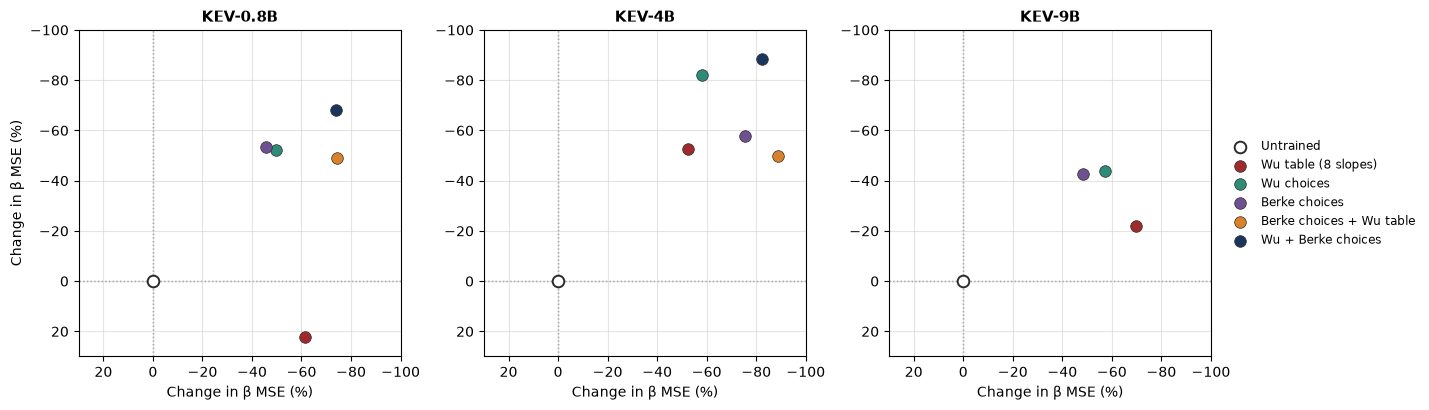

Note. Each point is one training regime. x-axis: Kriner 2026; y-axis: mean of Grummon 2025 and Kreps 2020. Both axes show the percentage change in population β MSE versus the untrained model (open circle at the origin) and are reversed, so up and right are better. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). Missing points: runs not finished yet.


In [234]:
OVERVIEW_MODELS = MODEL_SLUGS
OVERVIEW_SLUGS = (
    "row2_wu_table_anchored",
    "row2b_wu_ce_oracle",
    "row3_berke_ce_only",
    "row4_hybrid_berke_ce_wu_table_anchored",
    "row5_full_berke_wu_ce_oracle",
)
OVERVIEW_STEP = {
    "row2_wu_table_anchored": "2",
    "row2b_wu_ce_oracle": "1, 2",
    "row3_berke_ce_only": "1, 3",
    "row4_hybrid_berke_ce_wu_table_anchored": "3",
    "row5_full_berke_wu_ce_oracle": "1, 3",
}
OVERVIEW_DATA_USED = {
    "row2_wu_table_anchored": ("", "✓", ""),
    "row2b_wu_ce_oracle": ("✓", "", ""),
    "row3_berke_ce_only": ("", "", "✓"),
    "row4_hybrid_berke_ce_wu_table_anchored": ("", "✓", "✓"),
    "row5_full_berke_wu_ce_oracle": ("✓", "", "✓"),
}
TEST_KEYS = ("grummon", "covid")


def pct_change_vs_base(model_slug: str, slug: str, ds_key: str) -> float:
    sub = regimes_by_model[model_slug]
    base_value = float(sub.loc[BASE_SLUG, f"{ds_key}_mse"])
    value = float(sub.loc[slug, f"{ds_key}_mse"])
    return 100.0 * (value - base_value) / base_value


def test_mean_pct_change(model_slug: str, slug: str) -> float:
    """Mean over the two held-out test sets of the % change in β MSE vs. untrained."""
    changes = []
    for ds_key in TEST_KEYS:
        changes.append(pct_change_vs_base(model_slug, slug, ds_key))
    return float(np.mean(changes))


overview_rows = []
for slug in OVERVIEW_SLUGS:
    wu_choices, wu_table, berke_choices = OVERVIEW_DATA_USED[slug]
    row = {
        ("", "Trained on"): STORY_LABELS[slug],
        ("", "Step"): OVERVIEW_STEP[slug],
        ("Data used", "Wu choices"): wu_choices,
        ("Data used", "Wu table"): wu_table,
        ("Data used", "Berke choices"): berke_choices,
    }
    for model_slug in OVERVIEW_MODELS:
        kriner_change = pct_change_vs_base(model_slug, slug, "kriner")
        test_change = test_mean_pct_change(model_slug, slug)
        row[(MODEL_DISPLAY[model_slug], "Kriner 2026 †")] = format_pct(kriner_change)
        row[(MODEL_DISPLAY[model_slug], "Test mean")] = format_pct(test_change)
    overview_rows.append(row)

overview_df = pd.DataFrame(overview_rows)
overview_df.columns = pd.MultiIndex.from_tuples(overview_df.columns)
overview_df = overview_df.set_index([("", "Trained on")])
overview_df.index.name = "Trained on"
print_caption("Table 0", "Overview of Training Regimes")
display(overview_df)
print_note("Values are percentage changes in population β MSE versus the untrained model; negative is better. Test mean = mean of the changes on Grummon 2025 and Kreps 2020. Wu table runs use the KL anchor (α = 0.005). Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.")

OVERVIEW_AXIS_LIMITS = (30.0, -100.0)

print_caption("Figure 0", "Change in β MSE on Kriner 2026 Versus the Held-Out Test Sets")

fig, axes = plt.subplots(1, len(OVERVIEW_MODELS), figsize=(3.9 * len(OVERVIEW_MODELS) + 2.7, 4.2))
for ax, model_slug in zip(axes, OVERVIEW_MODELS):
    ax.axhline(0.0, color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.0, zorder=1)
    ax.axvline(0.0, color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.0, zorder=1)
    ax.scatter([0.0], [0.0], s=70, facecolors="white", edgecolors=NEUTRALS["text"], linewidths=1.4, zorder=3, label=STORY_LABELS[BASE_SLUG])
    for slug in OVERVIEW_SLUGS:
        x_value = pct_change_vs_base(model_slug, slug, "kriner")
        y_value = test_mean_pct_change(model_slug, slug)
        ax.scatter([x_value], [y_value], s=70, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.5, zorder=3, label=STORY_LABELS[slug])
    ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
    ax.set_xlabel("Change in β MSE (%)")
    ax.grid(color=NEUTRALS["grid"], alpha=0.6)
    ax.set_xlim(OVERVIEW_AXIS_LIMITS)
    ax.set_ylim(OVERVIEW_AXIS_LIMITS)

axes[0].set_ylabel("Change in β MSE (%)")
axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.tight_layout()
plt.show()
print_note("Each point is one training regime. x-axis: Kriner 2026; y-axis: mean of Grummon 2025 and Kreps 2020. Both axes show the percentage change in population β MSE versus the untrained model (open circle at the origin) and are reversed, so up and right are better. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). Missing points: runs not finished yet.")

---
## Step 1 — Microdata Fine-Tuning Transfers to Unseen Domains (Untrained vs. `Row 2b`, `Row 3`, `Row 5`)

In [235]:
STEP1_MODELS = MODEL_SLUGS
STEP1_SLUGS = (
    "row1_base_untrained",
    "row2b_wu_ce_oracle",
    "row3_berke_ce_only",
    "row5_full_berke_wu_ce_oracle",
)

print_caption("Table 1", "Population β MSE After Microdata Fine-Tuning")
display(build_mse_styler(STEP1_MODELS, STEP1_SLUGS, STORY_COLUMNS))
print_note("Values are population β MSE ×10³, with the percentage change versus the untrained model in parentheses; lower is better. Bold marks the lowest value per model and column. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.")

Table 1
Population β MSE After Microdata Fine-Tuning


Note. Values are population β MSE ×10³, with the percentage change versus the untrained model in parentheses; lower is better. Bold marks the lowest value per model and column. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.


Figure 1
Microdata Fine-Tuning on the Held-Out Test Sets


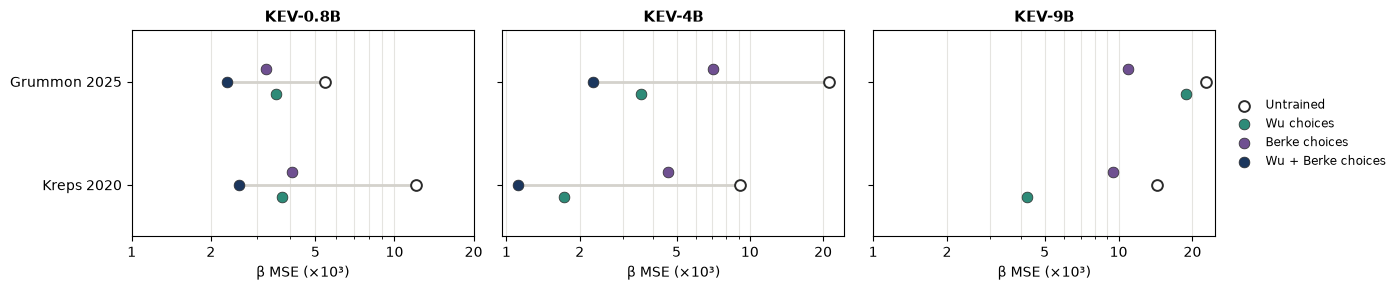

Note. Open circles are the untrained model; filled circles are fine-tuned runs. Population β MSE ×10³ on a log scale; lower is better. The grey bar joins the untrained model to the microdata reference, Wu + Berke choices. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets. Missing points: runs not finished yet.


In [236]:
print_caption("Figure 1", "Microdata Fine-Tuning on the Held-Out Test Sets")
plot_dot_panels(
    models=STEP1_MODELS,
    slugs=STEP1_SLUGS,
    datasets=(
        ("grummon", "Grummon 2025"),
        ("covid", "Kreps 2020"),
    ),
    y_offsets={
        "row1_base_untrained": 0.0,
        "row2b_wu_ce_oracle": 0.12,
        "row3_berke_ce_only": -0.12,
        "row5_full_berke_wu_ce_oracle": 0.0,
    },
    x_ticks=(1, 2, 5, 10, 20),
    reference_slug="row5_full_berke_wu_ce_oracle",
)
print_note("Open circles are the untrained model; filled circles are fine-tuned runs. Population β MSE ×10³ on a log scale; lower is better. The grey bar joins the untrained model to the microdata reference, Wu + Berke choices. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets. Missing points: runs not finished yet.")

---
## Step 2 — A Published Table Teaches the Study's Slopes (Untrained vs. `Row 2` KL-anchored vs. `Row 2b`)

In [237]:
STEP2_MODELS = MODEL_SLUGS
STEP2_SLUGS = (
    "row1_base_untrained",
    "row2_wu_table_anchored",
    "row2b_wu_ce_oracle",
)

print_caption("Table 2", "Wu's Table Versus Wu's Choices")
display(build_mse_styler(STEP2_MODELS, STEP2_SLUGS, STORY_COLUMNS))
print_note("Wu table = 8 OLS slopes reproduced from Wu 2025's specification, trained with the population β-loss and the KL anchor (α = 0.005). Wu choices = Wu's 18,591 respondent choices. Values are population β MSE ×10³, with the percentage change versus the untrained model in parentheses; lower is better. Bold marks the lowest value per model and column. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.")

Table 2
Wu's Table Versus Wu's Choices


Note. Wu table = 8 OLS slopes reproduced from Wu 2025's specification, trained with the population β-loss and the KL anchor (α = 0.005). Wu choices = Wu's 18,591 respondent choices. Values are population β MSE ×10³, with the percentage change versus the untrained model in parentheses; lower is better. Bold marks the lowest value per model and column. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.


Figure 2
Wu's Table Versus Wu's Choices


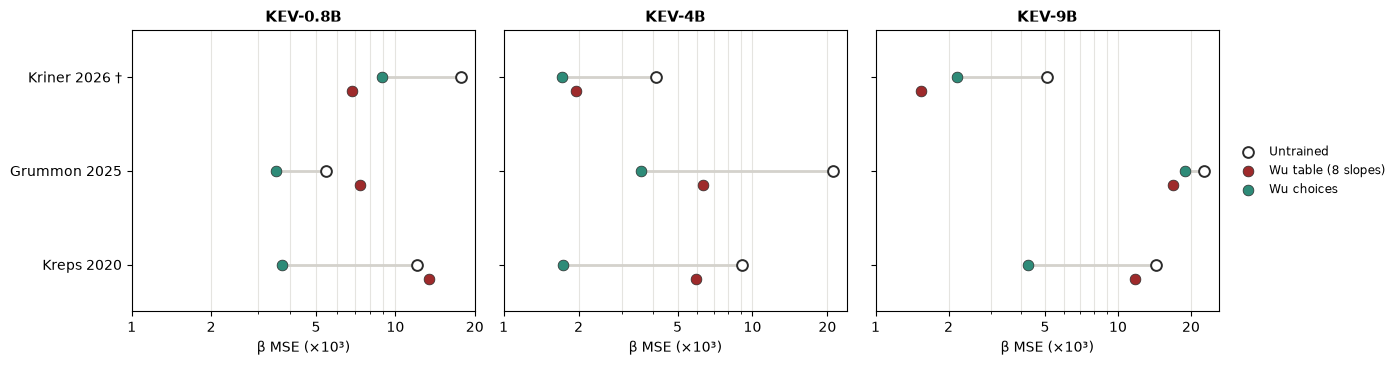

Note. Open circles are the untrained model; filled circles are fine-tuned runs. Population β MSE ×10³ on a log scale; lower is better. Hollow red circles are the Wu table without the KL anchor (α = 0), shown for comparison. The grey bar joins the untrained model to the microdata reference, Wu choices. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). Missing points: runs not finished yet.


In [230]:
print_caption("Figure 2", "Wu's Table Versus Wu's Choices")
plot_dot_panels(
    models=STEP2_MODELS,
    slugs=(
        "row1_base_untrained",
        "row2_wu_table_anchored",
        # "row2_ablation_wu_table_no_kl",
        "row2b_wu_ce_oracle",
    ),
    datasets=(
        ("kriner", "Kriner 2026 †"),
        ("grummon", "Grummon 2025"),
        ("covid", "Kreps 2020"),
    ),
    y_offsets={
        "row1_base_untrained": 0.0,
        "row2_wu_table_anchored": 0.15,
        # "row2_ablation_wu_table_no_kl": 0.3,
        "row2b_wu_ce_oracle": 0.0,
    },
    x_ticks=(1, 2, 5, 10, 20),
    reference_slug="row2b_wu_ce_oracle",
)
print_note("Open circles are the untrained model; filled circles are fine-tuned runs. Population β MSE ×10³ on a log scale; lower is better. Hollow red circles are the Wu table without the KL anchor (α = 0), shown for comparison. The grey bar joins the untrained model to the microdata reference, Wu choices. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). Missing points: runs not finished yet.")

---
## Step 3 — Your Microdata + Another Study's Table (Untrained vs. `Row 3` vs. `Row 4` KL-anchored vs. `Row 5`)

In [238]:
STEP3_MODELS = MODEL_SLUGS
STEP3_SLUGS = (
    "row1_base_untrained",
    "row3_berke_ce_only",
    "row4_hybrid_berke_ce_wu_table_anchored",
    "row5_full_berke_wu_ce_oracle",
)

print_caption("Table 3", "Berke Choices Plus Wu's Table Versus Wu + Berke Choices")
display(build_mse_styler(STEP3_MODELS, STEP3_SLUGS, STORY_COLUMNS))
print_note("Berke choices + Wu table = Berke's 36,297 choices plus Wu's 8 reproduced OLS slopes, with the KL anchor (α = 0.005). Values are population β MSE ×10³, with the percentage change versus the untrained model in parentheses; lower is better. Bold marks the lowest value per model and column. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.")

Table 3
Berke Choices Plus Wu's Table Versus Wu + Berke Choices


Note. Berke choices + Wu table = Berke's 36,297 choices plus Wu's 8 reproduced OLS slopes, with the KL anchor (α = 0.005). Values are population β MSE ×10³, with the percentage change versus the untrained model in parentheses; lower is better. Bold marks the lowest value per model and column. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.


Figure 3
Berke Choices Plus Wu's Table Versus Wu + Berke Choices


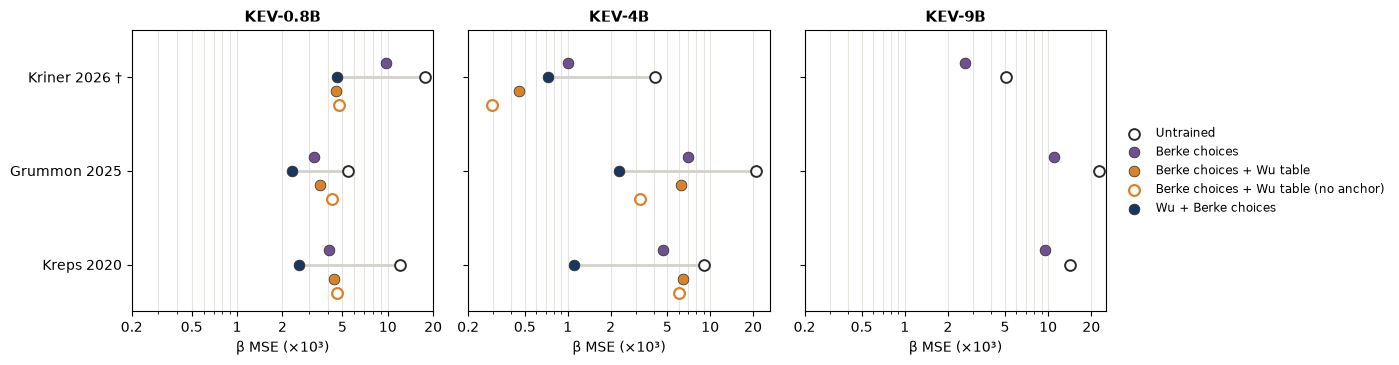

Note. Open circles are the untrained model; filled circles are fine-tuned runs. Population β MSE ×10³ on a log scale; lower is better. Hollow orange circles are Berke choices + Wu table without the KL anchor (α = 0), shown for comparison. The grey bar joins the untrained model to the microdata reference, Wu + Berke choices. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). Missing points: runs not finished yet.


In [239]:
print_caption("Figure 3", "Berke Choices Plus Wu's Table Versus Wu + Berke Choices")
plot_dot_panels(
    models=STEP3_MODELS,
    slugs=(
        "row1_base_untrained",
        "row3_berke_ce_only",
        "row4_hybrid_berke_ce_wu_table_anchored",
        "row4_hybrid_berke_ce_wu_table_no_kl",
        "row5_full_berke_wu_ce_oracle",
    ),
    datasets=(
        ("kriner", "Kriner 2026 †"),
        ("grummon", "Grummon 2025"),
        ("covid", "Kreps 2020"),
    ),
    y_offsets={
        "row1_base_untrained": 0.0,
        "row3_berke_ce_only": -0.15,
        "row4_hybrid_berke_ce_wu_table_anchored": 0.15,
        "row4_hybrid_berke_ce_wu_table_no_kl": 0.3,
        "row5_full_berke_wu_ce_oracle": 0.0,
    },
    x_ticks=(0.2, 0.5, 1, 2, 5, 10, 20),
    reference_slug="row5_full_berke_wu_ce_oracle",
)
print_note("Open circles are the untrained model; filled circles are fine-tuned runs. Population β MSE ×10³ on a log scale; lower is better. Hollow orange circles are Berke choices + Wu table without the KL anchor (α = 0), shown for comparison. The grey bar joins the untrained model to the microdata reference, Wu + Berke choices. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). Missing points: runs not finished yet.")

---
## Step 4 — Where the Table Helps: Kriner 2026 Flight Slopes by Attribute (`Row 3` vs. `Row 4` KL-anchored vs. `Row 5`)

Figure 4
Kriner 2026 Slope Errors by Attribute


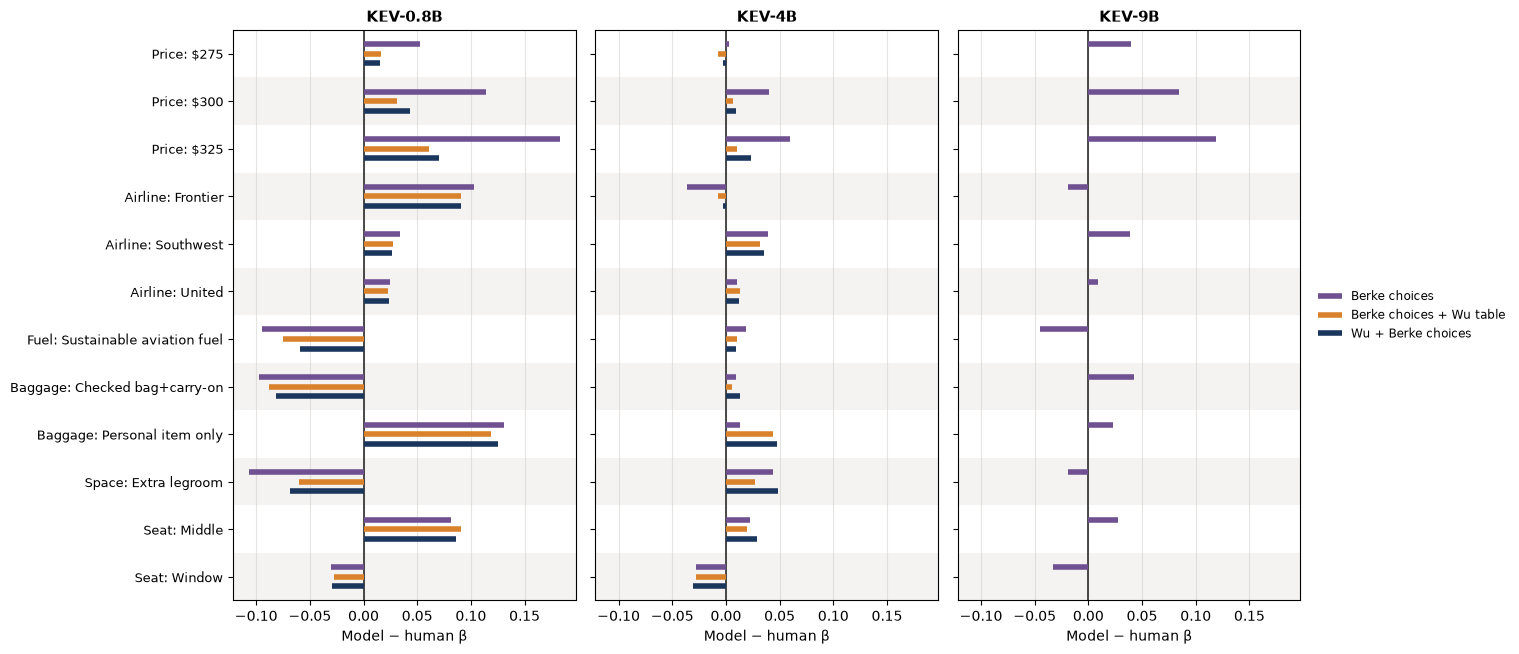

Note. Bars show model minus human population β for each Kriner 2026 attribute level; 0 means the model matches humans. Price terms are listed first. Values are in Table A6. † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). Empty panels or bars: runs not finished yet.


In [240]:
STEP4_MODELS = MODEL_SLUGS
STEP4_SLUGS = (
    "row3_berke_ce_only",
    "row4_hybrid_berke_ce_wu_table_anchored",
    "row5_full_berke_wu_ce_oracle",
)
STEP4_Y_OFFSETS = {
    "row3_berke_ce_only": -0.2,
    "row4_hybrid_berke_ce_wu_table_anchored": 0.0,
    "row5_full_berke_wu_ce_oracle": 0.2,
}


def load_kriner_human_betas(model_slug: str) -> pd.Series:
    """Human Kriner 2026 slopes (the same for every run) from the first finished run of this model."""
    for slug in TRAINED_SLUGS:
        run_dir = find_run_dir(model_slug, slug)
        if run_is_finished(run_dir):
            _, betas = load_paper_run(run_dir).best_validation["kriner2026"]
            return betas["human_pop_beta"]
    raise FileNotFoundError(f"No finished run for {model_slug} in {REGIME_RUN_ROOTS}")


def load_kriner_betas(model_slug: str, slug: str, human_betas: pd.Series) -> pd.DataFrame:
    """Per-term Kriner 2026 population slopes at the run's best.pt; model slopes are NaN if the run is not finished yet."""
    run_dir = find_run_dir(model_slug, slug)
    if not run_is_finished(run_dir):
        return pd.DataFrame({"human_pop_beta": human_betas, "model_pop_beta": np.nan})
    _, betas = load_paper_run(run_dir).best_validation["kriner2026"]
    if list(betas.index) != list(human_betas.index):
        raise ValueError(f"{model_slug}/{slug}: Kriner terms {list(betas.index)} != {list(human_betas.index)}")
    return betas[["human_pop_beta", "model_pop_beta"]]


kriner_betas_by_model = {}
for model_slug in STEP4_MODELS:
    kriner_betas_by_model[model_slug] = {}
    human_betas = load_kriner_human_betas(model_slug)
    for slug in STEP4_SLUGS:
        kriner_betas_by_model[model_slug][slug] = load_kriner_betas(model_slug, slug, human_betas)

all_kriner_terms = list(kriner_betas_by_model[STEP4_MODELS[0]][STEP4_SLUGS[0]].index)
price_terms = [term for term in all_kriner_terms if term.startswith("Price:")]
if len(price_terms) == 0:
    raise ValueError(f"No price terms in Kriner 2026: {all_kriner_terms}")
other_terms = [term for term in all_kriner_terms if not term.startswith("Price:")]
kriner_terms = price_terms + other_terms
y_positions = np.arange(len(kriner_terms))

print_caption("Figure 4", "Kriner 2026 Slope Errors by Attribute")
fig, axes = plt.subplots(1, len(STEP4_MODELS), figsize=(3.8 * len(STEP4_MODELS) + 3.9, 0.42 * len(kriner_terms) + 1.6), sharey=True, sharex=True)
for ax, model_slug in zip(axes, STEP4_MODELS):
    ax.axvline(0.0, color=NEUTRALS["text"], linewidth=1.2, zorder=2)
    for y in y_positions:
        if y % 2 == 1:
            ax.axhspan(y - 0.5, y + 0.5, color=NEUTRALS["grid"], alpha=0.25, zorder=0, linewidth=0)
    for slug in STEP4_SLUGS:
        betas = kriner_betas_by_model[model_slug][slug].loc[kriner_terms]
        errors = (betas["model_pop_beta"] - betas["human_pop_beta"]).to_numpy(dtype=float)
        y_shifted = y_positions + STEP4_Y_OFFSETS[slug]
        ax.hlines(y_shifted, 0.0, errors, color=STORY_COLORS[slug], linewidth=4.0, zorder=3, label=STORY_LABELS[slug])
    ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
    ax.set_xlabel("Model − human β")
    ax.grid(axis="x", color=NEUTRALS["grid"], alpha=0.6)

axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(kriner_terms, fontsize=9)
axes[0].set_ylim(-0.5, len(kriner_terms) - 0.5)
axes[0].invert_yaxis()
axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.tight_layout()
plt.show()
print_note("Bars show model minus human population β for each Kriner 2026 attribute level; 0 means the model matches humans. Price terms are listed first. Values are in Table A6. † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). Empty panels or bars: runs not finished yet.")

Figure 5
Kriner 2026 Population β by Attribute: Humans and Models


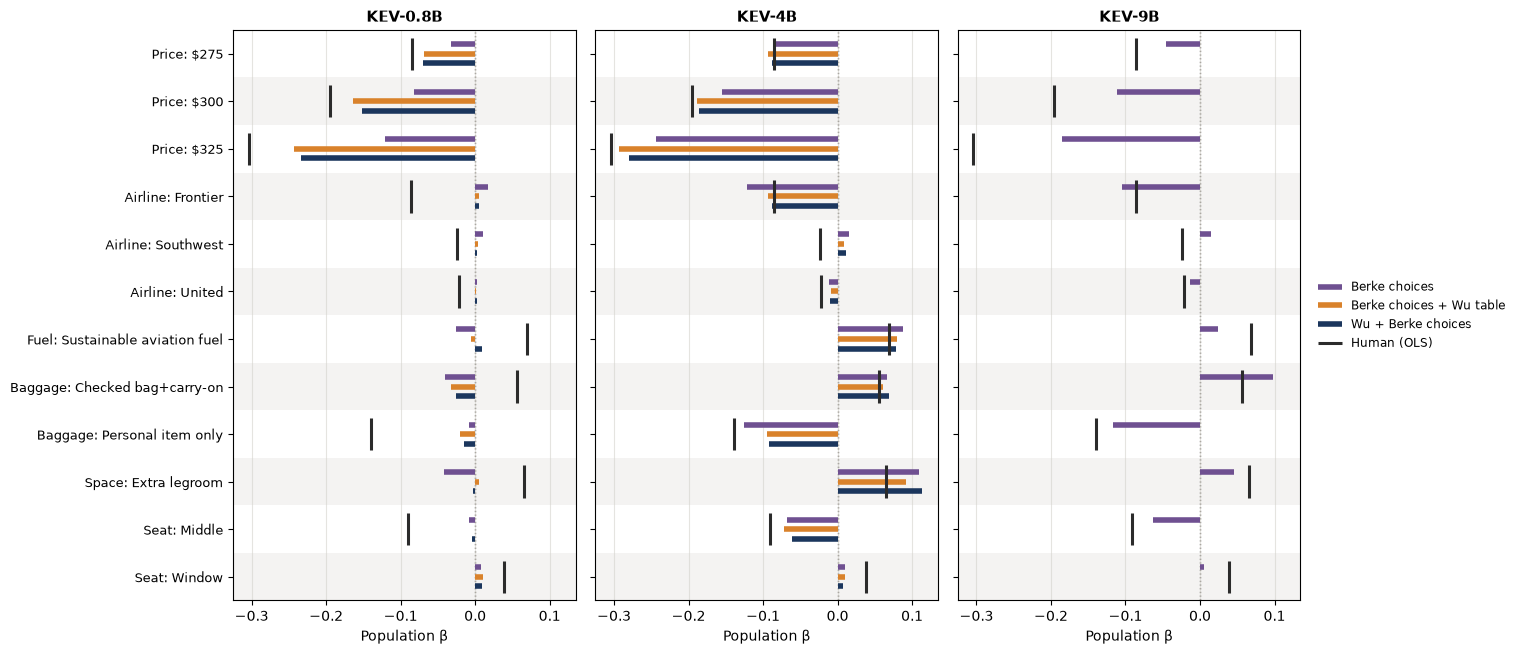

Note. Bars show each model's population β for each Kriner 2026 attribute level; the black tick marks the human OLS slope on the same row. A bar that ends at the tick matches humans. Price terms are listed first. Figure 4 shows the same values as model minus human; numbers are in Table A6. † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). Empty panels or bars: runs not finished yet.


In [241]:
HUMAN_TICK_HALF_HEIGHT = 0.34

print_caption("Figure 5", "Kriner 2026 Population β by Attribute: Humans and Models")
fig, axes = plt.subplots(1, len(STEP4_MODELS), figsize=(3.8 * len(STEP4_MODELS) + 3.9, 0.42 * len(kriner_terms) + 1.6), sharey=True, sharex=True)
for ax, model_slug in zip(axes, STEP4_MODELS):
    ax.axvline(0.0, color=NEUTRALS["ref_line"], linewidth=1.0, linestyle=":", zorder=1)
    for y in y_positions:
        if y % 2 == 1:
            ax.axhspan(y - 0.5, y + 0.5, color=NEUTRALS["grid"], alpha=0.25, zorder=0, linewidth=0)

    for slug in STEP4_SLUGS:
        betas = kriner_betas_by_model[model_slug][slug].loc[kriner_terms]
        model_values = betas["model_pop_beta"].to_numpy(dtype=float)
        y_shifted = y_positions + STEP4_Y_OFFSETS[slug]
        ax.hlines(y_shifted, 0.0, model_values, color=STORY_COLORS[slug], linewidth=4.0, zorder=3, label=STORY_LABELS[slug])

    human_values = kriner_betas_by_model[model_slug][STEP4_SLUGS[0]].loc[kriner_terms, "human_pop_beta"].to_numpy(dtype=float)
    ax.vlines(human_values, y_positions - HUMAN_TICK_HALF_HEIGHT, y_positions + HUMAN_TICK_HALF_HEIGHT, color=NEUTRALS["text"], linewidth=2.2, zorder=4, label="Human (OLS)")

    ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
    ax.set_xlabel("Population β")
    ax.grid(axis="x", color=NEUTRALS["grid"], alpha=0.6)

axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(kriner_terms, fontsize=9)
axes[0].set_ylim(-0.5, len(kriner_terms) - 0.5)
axes[0].invert_yaxis()
axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.tight_layout()
plt.show()
print_note("Bars show each model's population β for each Kriner 2026 attribute level; the black tick marks the human OLS slope on the same row. A bar that ends at the tick matches humans. Price terms are listed first. Figure 4 shows the same values as model minus human; numbers are in Table A6. † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). Empty panels or bars: runs not finished yet.")

---
## Ablation — The KL Anchor (`Row 2` and `Row 4` with α = 0.005 vs. α = 0; α sweep)

In [242]:
ABLATION_MODELS = MODEL_SLUGS
ABLATION_PAIRS = (
    ("a", "Wu Table With and Without the KL Anchor", "row2_wu_table_anchored", "row2_ablation_wu_table_no_kl"),
    ("b", "Berke Choices Plus Wu Table With and Without the KL Anchor", "row4_hybrid_berke_ce_wu_table_anchored", "row4_hybrid_berke_ce_wu_table_no_kl"),
)
# The anchor is a design choice, so it is judged on the validation set alone; the held-out test sets stay out of it
ABLATION_COLUMNS = (("kriner", "Kriner 2026 †"),)
ABLATION_ROLES_NOTE = "† Kriner 2026 (flight conjoint) is the validation set: it selects each run's checkpoint (best.pt) and is the only data set used to judge the anchor. The held-out test sets (Grummon 2025, Kreps 2020) are left out of this ablation so that they do not inform the method."

for letter, title, anchored_slug, no_anchor_slug in ABLATION_PAIRS:
    print_caption(f"Table 4{letter}", title)
    display(build_mse_styler(ABLATION_MODELS, (BASE_SLUG, anchored_slug, no_anchor_slug), ABLATION_COLUMNS))
    print_note(f"With anchor = KL(p₀‖p_θ) on Wu's tasks with weight α = 0.005; no anchor = α = 0. Values are population β MSE ×10³ at best.pt, with the percentage change versus the untrained model in parentheses; lower is better. Bold marks the lower of the two runs per model. {ABLATION_ROLES_NOTE} NaN = run not finished yet.")


Table 4a
Wu Table With and Without the KL Anchor


Note. With anchor = KL(p₀‖p_θ) on Wu's tasks with weight α = 0.005; no anchor = α = 0. Values are population β MSE ×10³, with the percentage change versus the untrained model in parentheses; lower is better. Bold marks the lower of the two runs per model and column. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.
Table 4b
Berke Choices Plus Wu Table With and Without the KL Anchor


Note. With anchor = KL(p₀‖p_θ) on Wu's tasks with weight α = 0.005; no anchor = α = 0. Values are population β MSE ×10³, with the percentage change versus the untrained model in parentheses; lower is better. Bold marks the lower of the two runs per model and column. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.


Figure 6
Training Trajectories of the Wu Table With and Without the KL Anchor


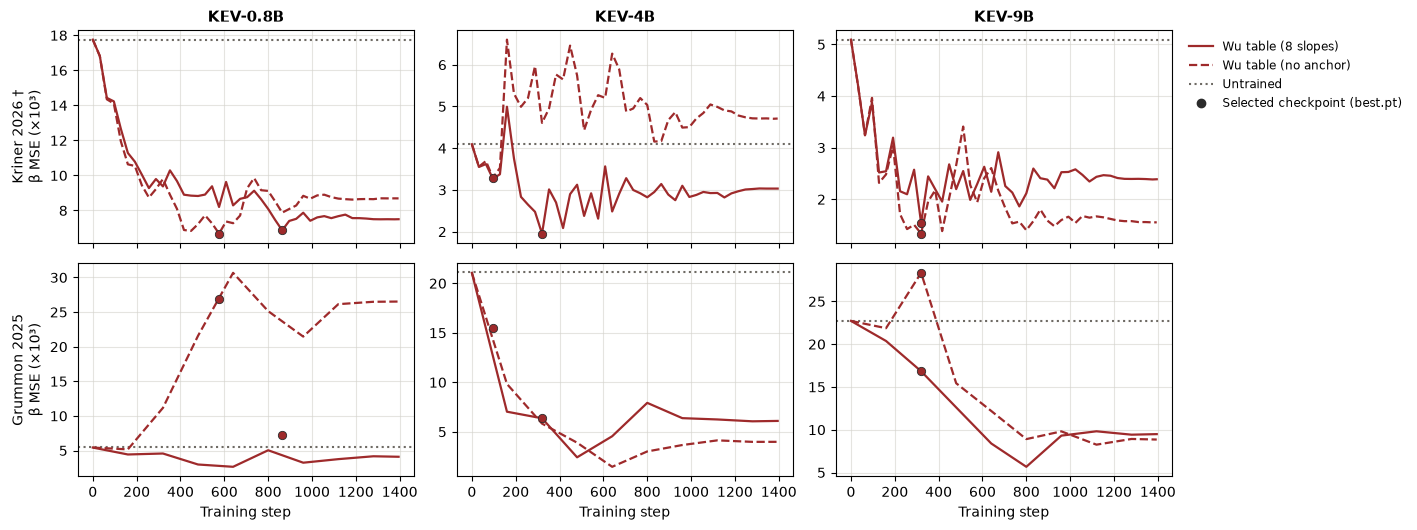

Note. Population β MSE ×10³ over training; lower is better. Solid lines: KL anchor (α = 0.005); dashed lines: no anchor (α = 0). Dots mark each run's selected checkpoint (best.pt), chosen on Kriner 2026 alone; the dotted line is the untrained model. Kriner 2026 is evaluated every 32 steps, Grummon 2025 every 160. Kreps 2020 is evaluated only at best.pt (Table 4). Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). Missing lines: runs not finished yet.
Figure 7
Training Trajectories of Berke Choices Plus Wu Table With and Without the KL Anchor


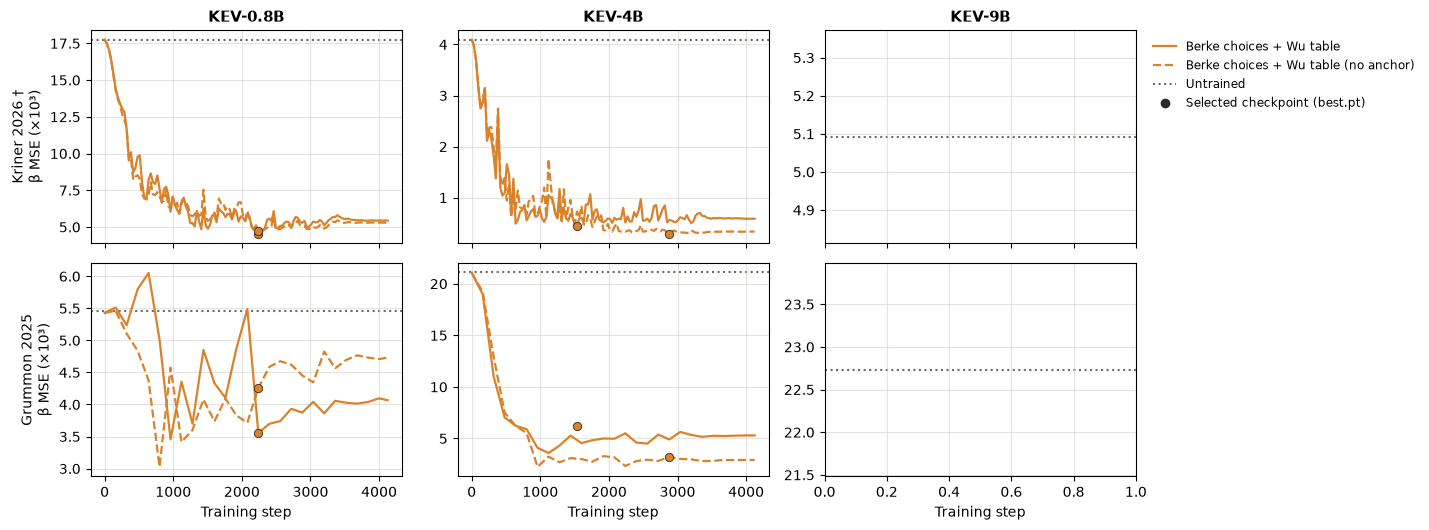

Note. Population β MSE ×10³ over training; lower is better. Solid lines: KL anchor (α = 0.005); dashed lines: no anchor (α = 0). Dots mark each run's selected checkpoint (best.pt), chosen on Kriner 2026 alone; the dotted line is the untrained model. Kriner 2026 is evaluated every 32 steps, Grummon 2025 every 160. Kreps 2020 is evaluated only at best.pt (Table 4). Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). Missing lines: runs not finished yet.


In [243]:
def plot_anchor_trajectories(anchored_slug: str, no_anchor_slug: str) -> None:
    """Kriner 2026 β MSE over training, one panel per model; solid = anchor, dashed = no anchor, dot = best.pt."""
    fig, axes = plt.subplots(1, len(ABLATION_MODELS), figsize=(3.8 * len(ABLATION_MODELS) + 3.0, 3.2), squeeze=False)
    axes = axes[0]
    for ax, model_slug in zip(axes, ABLATION_MODELS):
        base_value = float(regimes_by_model[model_slug].loc[BASE_SLUG, "kriner_mse"]) * MSE_SCALE
        ax.axhline(base_value, color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.5, zorder=1)
        for slug, linestyle in ((anchored_slug, "-"), (no_anchor_slug, "--")):
            run_dir = find_run_dir(model_slug, slug)
            if not run_is_finished(run_dir):
                continue
            result = load_paper_run(run_dir)
            series = result.val_history_df["kriner2026/beta_mse"].dropna() * MSE_SCALE
            ax.plot(series.index, series.values, color=STORY_COLORS[slug], linestyle=linestyle, linewidth=1.6, zorder=2)
            best_step = int(result.best["step"])
            best_metrics, _ = result.best_validation["kriner2026"]
            ax.scatter([best_step], [float(best_metrics["beta_mse"]) * MSE_SCALE], s=36, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.6, zorder=3)
        ax.grid(color=NEUTRALS["grid"], alpha=0.6)
        ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
        ax.set_xlabel("Training step")
    axes[0].set_ylabel("β MSE (×10³)")

    legend_handles = [
        plt.Line2D([], [], color=STORY_COLORS[anchored_slug], linestyle="-", linewidth=1.6, label=STORY_LABELS[anchored_slug]),
        plt.Line2D([], [], color=STORY_COLORS[no_anchor_slug], linestyle="--", linewidth=1.6, label=STORY_LABELS[no_anchor_slug]),
        plt.Line2D([], [], color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.5, label=STORY_LABELS[BASE_SLUG]),
        plt.Line2D([], [], color=NEUTRALS["text"], marker="o", linestyle="", markersize=6, label="Selected checkpoint (best.pt)"),
    ]
    axes[-1].legend(handles=legend_handles, fontsize=8.5, loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False)
    fig.tight_layout()
    plt.show()


TRAJECTORY_NOTE = "Population β MSE ×10³ on Kriner 2026 over training, evaluated every 32 steps; lower is better. Solid lines: KL anchor (α = 0.005); dashed lines: no anchor (α = 0). Dots mark each run's selected checkpoint (best.pt); the dotted line is the untrained model. " + ABLATION_ROLES_NOTE + " Missing lines: runs not finished yet."

print_caption("Figure 6", "Kriner 2026 Over Training: Wu Table With and Without the KL Anchor")
plot_anchor_trajectories("row2_wu_table_anchored", "row2_ablation_wu_table_no_kl")
print_note(TRAJECTORY_NOTE)

print_caption("Figure 7", "Kriner 2026 Over Training: Berke Choices Plus Wu Table With and Without the KL Anchor")
plot_anchor_trajectories("row4_hybrid_berke_ce_wu_table_anchored", "row4_hybrid_berke_ce_wu_table_no_kl")
print_note(TRAJECTORY_NOTE)


In [219]:
SWEEP_SPECS = (
    ("a", "kev-0.8b", (LOCAL_PAPER_RUNS_ROOT / "kl_anchor_800m", PAPER_RUNS_ROOT / "kl_anchor_800m")),
    ("b", "kev-9b", (PAPER_RUNS_ROOT / "kl_anchor_9b",)),
)
SWEEP_DRIFT_WINDOW = 20


def format_mse_value(value: float) -> str:
    if np.isnan(value):
        return "NaN"
    return f"{value * MSE_SCALE:.2f}"


def collect_alpha_sweep(sweep_roots: tuple[Path, ...]) -> tuple[pd.DataFrame, list[str], set[float]]:
    """One row per α (plus untrained): KL drift from p₀ near best.pt, and Kriner 2026 β MSE at best.pt."""
    run_dirs = []
    for root in sweep_roots:
        for run_dir in sorted(root.iterdir()):
            if (run_dir / "run.json").exists():
                run_dirs.append(run_dir)
    if len(run_dirs) == 0:
        raise FileNotFoundError(f"No α-sweep runs in {sweep_roots}")

    keyed = []
    for run_dir in run_dirs:
        info = run_store.read_run_json(run_dir)
        keyed.append((float(info["identity"]["config"]["kl_anchor_alpha"]), float(info["identity"]["config"]["lr"]), info["status"], run_dir))
    keyed.sort()
    alphas = [alpha for alpha, _, _, _ in keyed]
    if len(set(alphas)) != len(alphas):
        raise ValueError(f"Duplicate α in {sweep_roots}: {alphas}")

    step0 = extract_step0_from_run_dir(keyed[0][3], ("kriner2026",))
    rows = [{
        "α": "Untrained",
        "KL drift from p₀": "0.00",
        "Kriner 2026 †": format_mse_value(float(step0["metrics"]["kriner2026/beta_mse"])),
    }]
    status_notes = []
    learning_rates = set()
    for alpha, lr, status, run_dir in keyed:
        result = load_paper_run(run_dir)
        if status != run_store.STATUS_FINISHED:
            rows.append({"α": f"{alpha:g}", "KL drift from p₀": "NaN", "Kriner 2026 †": "NaN"})
            status_notes.append(f"α = {alpha:g} was {status} at step {len(result.step_df)} and is not reported (NaN).")
            continue
        learning_rates.add(lr)
        best_step = int(result.best["step"])
        drift = result.step_df.loc[result.step_df.index <= best_step, "kl_anchor_loss"].dropna().tail(SWEEP_DRIFT_WINDOW)
        kriner_metrics, _ = result.best_validation["kriner2026"]
        rows.append({
            "α": f"{alpha:g}",
            "KL drift from p₀": f"{float(drift.mean()):.2f}",
            "Kriner 2026 †": format_mse_value(float(kriner_metrics["beta_mse"])),
        })
    return pd.DataFrame(rows).set_index("α"), status_notes, learning_rates


for letter, model_slug, sweep_roots in SWEEP_SPECS:
    sweep_df, status_notes, learning_rates = collect_alpha_sweep(sweep_roots)
    lr_text = ", ".join(f"{lr:g}" for lr in sorted(learning_rates))
    print_caption(f"Table 5{letter}", f"KL Anchor Weight Sweep on the Wu Table: {MODEL_DISPLAY[model_slug]}")
    display(sweep_df)
    print_note(
        f"Each row is one Wu table run with KL anchor weight α (α = 0: no anchor). KL drift from p₀ = mean KL(p₀‖p_θ) on Wu's tasks over the {SWEEP_DRIFT_WINDOW} logged steps up to best.pt (logged even when α = 0). "
        f"β MSE ×10³ at best.pt; lower is better. These sweep runs used learning rate {lr_text}; the paper's Wu table runs (Tables 2 and 4) use 5e-6 and α = 0.005. "
        + "".join(f"{status_note} " for status_note in status_notes) + ABLATION_ROLES_NOTE
    )

Table 5a
KL Anchor Weight Sweep on the Wu Table: KEV-0.8B


,KL drift from p₀,Kriner 2026 †,Grummon 2025
α,,,
Untrained,0.00,17.75,5.46
0,4.65,4.10,5.86
0.002,1.53,4.20,2.98
0.005,1.02,3.52,5.47
0.02,0.43,5.85,3.44
0.1,0.19,6.29,7.18
0.5,0.10,10.33,NaN


Note. Each row is one Wu table run with KL anchor weight α (α = 0: no anchor). KL drift from p₀ = mean KL(p₀‖p_θ) on Wu's tasks over the 20 logged steps up to best.pt (logged even when α = 0). β MSE ×10³ at best.pt; lower is better. These sweep runs used learning rate 1e-05; the paper's Wu table runs (Tables 2 and 4) use 5e-6 and α = 0.005. α = 0.5 was interrupted at step 1350; its Grummon 2025 value at best.pt was not computed (NaN). Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt).
Table 5b
KL Anchor Weight Sweep on the Wu Table: KEV-9B


,KL drift from p₀,Kriner 2026 †,Grummon 2025
α,,,
Untrained,0.00,5.09,22.72
0,1.65,0.99,17.25
0.002,0.92,1.49,18.40
0.005,0.66,1.58,22.31
0.01,0.60,1.99,12.54
0.05,0.23,2.21,16.18


Note. Each row is one Wu table run with KL anchor weight α (α = 0: no anchor). KL drift from p₀ = mean KL(p₀‖p_θ) on Wu's tasks over the 20 logged steps up to best.pt (logged even when α = 0). β MSE ×10³ at best.pt; lower is better. These sweep runs used learning rate 5e-06; the paper's Wu table runs (Tables 2 and 4) use 5e-6 and α = 0.005.  Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt).


---
## Appendix — Choice KL for Table 1

In [ ]:
table_a2_df = relabel_rows(build_metric_table(STEP1_MODELS, STEP1_SLUGS, "kl", STORY_COLUMNS).round(3))
print_caption("Table A2", "Choice KL for Table 1")
display(table_a2_df)
print_note("Choice KL = mean −log probability the model assigns to the option each respondent chose (the KL divergence from each observed choice); lower is better. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.")

table_a3_df = relabel_rows(build_metric_table(STEP2_MODELS, STEP2_SLUGS, "kl", STORY_COLUMNS).round(3))
print_caption("Table A3", "Choice KL for Table 2")
display(table_a3_df)
print_note("Choice KL = mean −log probability the model assigns to the option each respondent chose (the KL divergence from each observed choice); lower is better. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.")

table_a4_df = relabel_rows(build_metric_table(STEP3_MODELS, STEP3_SLUGS, "kl", STORY_COLUMNS).round(3))
print_caption("Table A4", "Choice KL for Table 3")
display(table_a4_df)
print_note("Choice KL = mean −log probability the model assigns to the option each respondent chose (the KL divergence from each observed choice); lower is better. Grummon 2025 (food warning labels) and Kreps 2020 (COVID-19 vaccines) are held-out test sets; † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.")

---
## Appendix — Kreps 2020 Slopes by Attribute (Table A5)

In [ ]:
KREPS_APPENDIX_SLUGS = (
    "row1_base_untrained",
    "row2_wu_table_anchored",
    "row2_ablation_wu_table_no_kl",
    "row2b_wu_ce_oracle",
    "row3_berke_ce_only",
    "row4_hybrid_berke_ce_wu_table_anchored",
    "row4_hybrid_berke_ce_wu_table_no_kl",
    "row5_full_berke_wu_ce_oracle",
)

for model_index, model_slug in enumerate(STEP4_MODELS):
    betas_by_slug = covid_betas_by_model[model_slug]
    columns = {"Human (OLS)": betas_by_slug[BASE_SLUG]["human_pop_beta"]}
    for slug in KREPS_APPENDIX_SLUGS:
        if slug in betas_by_slug:
            columns[STORY_LABELS[slug]] = betas_by_slug[slug]["model_pop_beta"]
        else:
            columns[STORY_LABELS[slug]] = pd.Series(np.nan, index=columns["Human (OLS)"].index)
    kreps_term_df = pd.DataFrame(columns)
    kreps_term_df.index.name = "Vaccine attribute level"
    squared_error = kreps_term_df.sub(kreps_term_df["Human (OLS)"], axis=0).pow(2)
    kreps_term_df.loc["β MSE vs. human"] = squared_error.mean()
    print_caption(f"Table A5{TABLE_LETTERS[model_index]}", f"Kreps 2020 Population β by Attribute: {MODEL_DISPLAY[model_slug]}")
    display(kreps_term_df.round(4))
    print_note("Kreps 2020 is a held-out test set. Human (OLS) = slope fitted on respondents' choices. The last row is β MSE versus human. Includes runs without the KL anchor. NaN = run not finished yet.")

---
## Appendix — Kriner 2026 Slopes by Attribute (Table A6)

In [ ]:
for model_index, model_slug in enumerate(STEP4_MODELS):
    betas_by_slug = kriner_betas_by_model[model_slug]
    columns = {"Human (OLS)": betas_by_slug[STEP4_SLUGS[0]]["human_pop_beta"]}
    for slug in STEP4_SLUGS:
        columns[STORY_LABELS[slug]] = betas_by_slug[slug]["model_pop_beta"]
    kriner_term_df = pd.DataFrame(columns)
    kriner_term_df.index.name = "Flight attribute level"
    squared_error = kriner_term_df.sub(kriner_term_df["Human (OLS)"], axis=0).pow(2)
    kriner_term_df.loc["β MSE vs. human"] = squared_error.mean()
    print_caption(f"Table A6{TABLE_LETTERS[model_index]}", f"Kriner 2026 Population β by Attribute: {MODEL_DISPLAY[model_slug]}")
    display(kriner_term_df.round(4))
    print_note("Values behind Figure 4. Human (OLS) = slope fitted on respondents' choices. The last row is β MSE versus human. † Kriner 2026 (flight conjoint) is the validation set and selects each run's checkpoint (best.pt). NaN = run not finished yet.")

---
## Appendix — Choice KL for Table 4 (Table A7)

In [ ]:
for letter, title, anchored_slug, no_anchor_slug in ABLATION_PAIRS:
    table_a7_df = relabel_rows(build_metric_table(ABLATION_MODELS, (BASE_SLUG, anchored_slug, no_anchor_slug), "kl", ABLATION_COLUMNS).round(3))
    print_caption(f"Table A7{letter}", f"Choice KL for Table 4{letter}")
    display(table_a7_df)
    print_note(f"Choice KL = mean −log probability the model assigns to the option each respondent chose (the KL divergence from each observed choice); lower is better. {ABLATION_ROLES_NOTE} NaN = run not finished yet.")